In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("retail_store_sales_cleaned.csv")

print("Dataset Shape:", df.shape)
print("\nQuantity Summary:")
print(df["Quantity"].describe())

print("\nTotal Spent Summary:")
print(df["Total Spent"].describe())

Dataset Shape: (10531, 11)

Quantity Summary:
count    10531.000000
mean         5.534707
std          2.860280
min          1.000000
25%          3.000000
50%          6.000000
75%          8.000000
max         10.000000
Name: Quantity, dtype: float64

Total Spent Summary:
count    10531.000000
mean       129.640063
std         94.550620
min          5.000000
25%         52.000000
50%        108.500000
75%        192.000000
max        410.000000
Name: Total Spent, dtype: float64


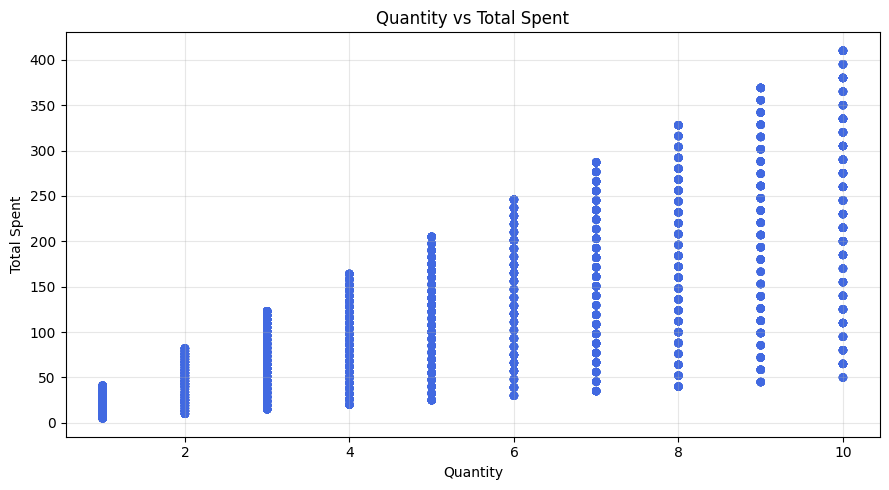

In [2]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Quantity"],
    df["Total Spent"],
    alpha=0.4,
    color="royalblue",
    edgecolors="none"
)

plt.title("Quantity vs Total Spent")
plt.xlabel("Quantity")
plt.ylabel("Total Spent")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [3]:

correlation = df["Quantity"].corr(df["Total Spent"])

print("Correlation:", round(correlation, 3))

if correlation > 0:
    print("Direction: Positive")
elif correlation < 0:
    print("Direction: Negative")
else:
    print("Direction: No linear correlation")

Correlation: 0.712
Direction: Positive


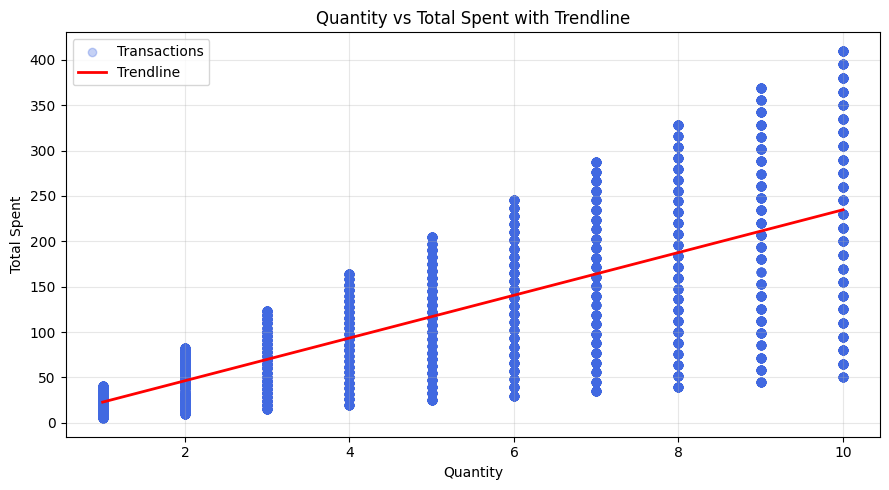

Slope: 23.54
Intercept: -0.67


In [4]:

import numpy as np

x = df["Quantity"]
y = df["Total Spent"]

slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(9, 5))

plt.scatter(x, y, alpha=0.3, color="royalblue", label="Transactions")
plt.plot(
    x.sort_values(),
    slope * x.sort_values() + intercept,
    color="red",
    linewidth=2,
    label="Trendline"
)

plt.title("Quantity vs Total Spent with Trendline")
plt.xlabel("Quantity")
plt.ylabel("Total Spent")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Slope:", round(slope, 2))
print("Intercept:", round(intercept, 2))

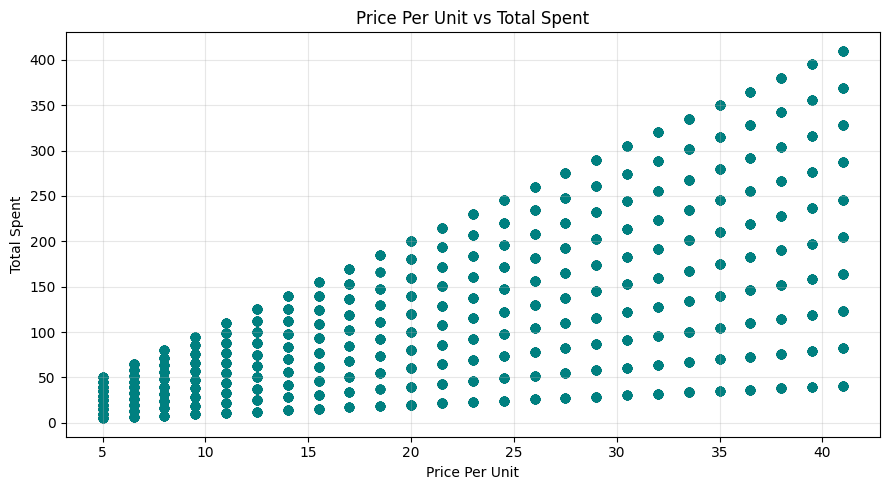

In [5]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Price Per Unit"],
    df["Total Spent"],
    alpha=0.4,
    color="teal"
)

plt.title("Price Per Unit vs Total Spent")
plt.xlabel("Price Per Unit")
plt.ylabel("Total Spent")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

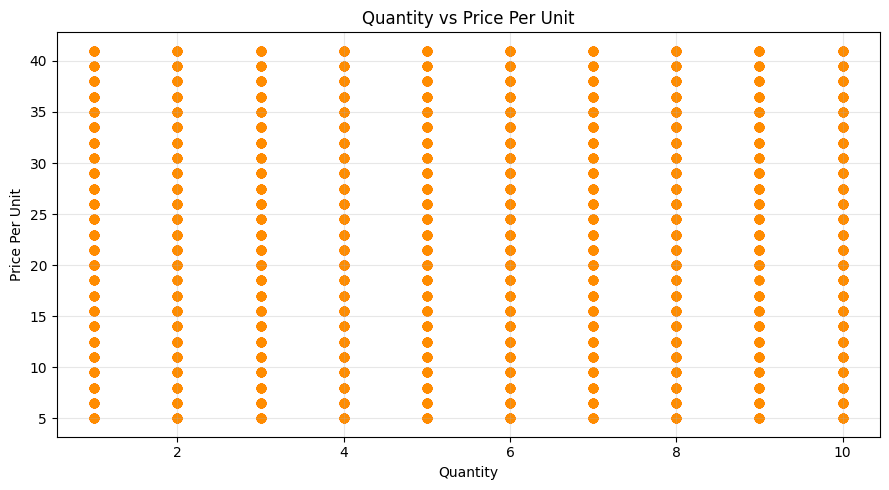

Correlation: 0.006


In [6]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Quantity"],
    df["Price Per Unit"],
    alpha=0.4,
    color="darkorange"
)

plt.title("Quantity vs Price Per Unit")
plt.xlabel("Quantity")
plt.ylabel("Price Per Unit")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Correlation:", round(df["Quantity"].corr(df["Price Per Unit"]), 3))

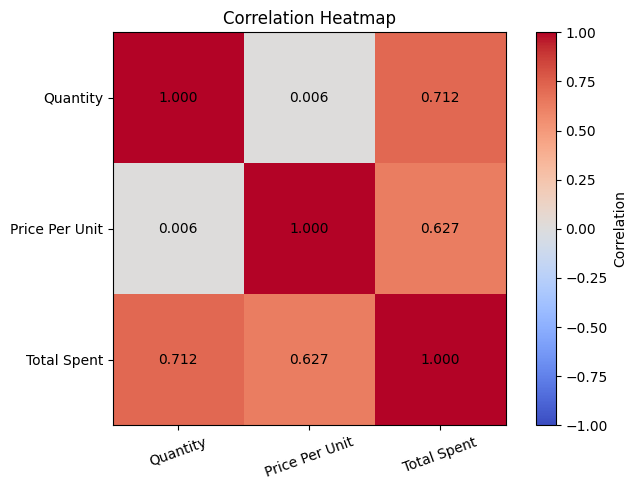

In [7]:
corr = df[["Quantity", "Price Per Unit", "Total Spent"]].corr()

plt.figure(figsize=(7, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

plt.xticks(range(len(corr.columns)), corr.columns, rotation=20)
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.3f}",
                 ha="center", va="center")

plt.colorbar(label="Correlation")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()